# EDA: продажи по складам, городам и категориям

Общий код (загрузка, сетка, метрики) - в `src/core.py`, модели - в `03_classifier.ipynb` и `04_regressor.ipynb`, сабмит - в `01_start.ipynb`.

Объём продаж везде = сумма `quantity`. Данные - только по 2026-07-26 включительно: `load_data()` отрезает остальное, так требует ТЗ. На графиках по неделям серым закрашены 9 недель теста - **27 июля - 27 сентября 2026** - и те же недели в 2024 и 2025 годах.
На каждый разрез три графика: доля в объёме, продажи по неделям (панель на значение, у каждой своя шкала Y), сезонный множитель (продажи за 9 недель теста к 8 неделям до отсечки, 2024 и 2025).

## Что уже известно о данных

- Продажи с **2024-01-01**; для обучения можно брать данные только **по 2026-07-26** (в файлах есть по 07-31 - `load_data()` их отрезает). Прогноз - **9 недель с 2026-07-27** (последняя неделя - 21-27 сентября), строка = неделя × склад × товар, `quantity` - сумма за неделю.
- В stock колонка товара называется `article`, а в ТЗ - `char_article`.
- В sales есть строки **только за дни с продажами** -> строим полную сетку и заполняем нулями (иначе все средние завышены).
- `quantity` целые, почти всегда 1-2 в день. По неделям нулей всё равно много: в сезон 2025 нулевые 56 % пар-недель, у 12 % пар за 9 недель ни одной продажи, у 14 % продажи каждую неделю; обычная ненулевая неделя - 2 штуки.
- В stock до 4 строк на один день/склад/товар (суммируем), отрицательный остаток - резерв. Продажи бывают и при нулевом остатке (клиента предупреждают, что товара нет): примерно треть продаж приходится на дни с остатком 0 -> "остаток 0" не значит "продаж не будет".
- `category_lvl_3` почти пустая; `characteristic` у каждого товара одна (атрибут товара).
- `sales_sum` и `discount_sum` - логарифмы (`np.log`, так сказано в ТЗ): перед суммированием по неделе - `np.exp`. Пустой `discount_sum` = скидки не было (0).
- 5 % пар дают ~45 % объёма продаж (они решают WAPE и RMSE); склады `warehouse_name_2` и `_3` - почти 60 % объёма.
- Пар с продажами по 26.07 - 8777, полное произведение 11 × 799 = 8789 (12 пар ни разу не продавались).
- Динамика неровная не из-за ошибок в данных: по FAQ (п. 8), процессы внутри компании в разные моменты менялись, а с ними - объёмы и динамика продаж (например, склад `wh_10` появился в середине 2024). Задача - учесть эти сдвиги, чтобы извлекать пользу и из старых данных: признаки относительно недавнего уровня (тренды, доли), а не только абсолютные объёмы.

## 0. Данные и оформление графиков

In [1]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import sys; sys.path.insert(0, "../src")   # код проекта - в src/
from core import *

sales, stock = load_data()
print("sales:", sales.shape, sales.date.min().date(), "...", sales.date.max().date())
print("stock:", stock.shape, stock.date.min().date(), "...", stock.date.max().date())
sales.head()

sales: (1478827, 12) 2024-01-01 ... 2026-07-26
stock: (6092305, 4) 2023-12-13 ... 2026-07-26


,date,composite_division,cities_name,warehouse_name,category_lvl_1,category_lvl_2,category_lvl_3,article,characteristic,quantity,sales_sum,discount_sum
0,2024-01-01,composite_division_0,cities_name_0,warehouse_name_0,category_lvl_1_0,category_lvl_2_0,NaN,char_article_0,characteristic_0,2.0,7.429034,5.459302
1,2024-01-01,composite_division_0,cities_name_0,warehouse_name_0,category_lvl_1_1,category_lvl_2_1,NaN,char_article_1,characteristic_0,1.0,9.613652,7.798864
2,2024-01-01,composite_division_0,cities_name_0,warehouse_name_0,category_lvl_1_2,category_lvl_2_2,NaN,char_article_2,characteristic_0,1.0,9.237081,7.258904
3,2024-01-01,composite_division_0,cities_name_0,warehouse_name_0,category_lvl_1_3,category_lvl_2_3,NaN,char_article_3,characteristic_1,1.0,9.066837,7.094100
4,2024-01-01,composite_division_0,cities_name_1,warehouse_name_1,category_lvl_1_2,category_lvl_2_2,NaN,char_article_4,characteristic_0,1.0,9.237083,7.258905


In [2]:
stock.head()

,date,warehouse_name,article,stock
0,2023-12-13,warehouse_name_0,char_article_119,1
1,2023-12-13,warehouse_name_3,char_article_62,135
2,2023-12-13,warehouse_name_3,char_article_268,3
3,2023-12-13,warehouse_name_7,char_article_258,1
4,2023-12-13,warehouse_name_3,char_article_14,19


In [3]:
# цвета: один акцентный для данных, серые для фона и подписей
SURFACE, OTHER, SEASON = "#fcfcfb", "#c3c2b7", "#f0efec"
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
SIGN = {True: RED, False: BLUE}   # выше / ниже обычного уровня

sns.set_theme(style="whitegrid", font_scale=0.8, rc={
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.titlesize": 9, "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "axes.edgecolor": OTHER,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": OTHER, "ytick.color": OTHER, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.linewidth": 0.8, "lines.linewidth": 1.4,
})

SEASONS = [(pd.Timestamp(c) + pd.Timedelta(days=1), pd.Timestamp(c) + pd.Timedelta(days=63))   # 9 недель после отсечки
           for c in (FOLDS["season2024"], FOLDS["season2025"], CUTOFF)]
PREFIXES = {"warehouse_name_": "wh_", "cities_name_": "city_", "composite_division_": "div_", "category_lvl_": "cat"}


def short(name):
    # warehouse_name_3 -> wh_3, category_lvl_2_17 -> cat2_17
    name = str(name)
    for long, s in PREFIXES.items():
        name = name.replace(long, s)
    return name


def volume(col):
    # объём продаж по значениям колонки, от большего к меньшему
    return sales.groupby(col).quantity.sum().sort_values(ascending=False)


def weekly(by=None):
    # продажи по неделям (столбцы = значения by); неполную последнюю неделю отбрасываем
    keys = [pd.Grouper(key="date", freq="W")] + ([by] if by else [])
    w = sales.groupby(keys).quantity.sum()
    w = w.unstack(fill_value=0) if by else w
    return w[w.index <= sales.date.max()]


def style_weekly(ax):
    # сезон теста серым, ось X по годам, Y от нуля
    for a, b in SEASONS:
        ax.axvspan(a, b, color=SEASON, lw=0, zorder=0)
    ax.set_xlim(sales.date.min(), SEASONS[-1][1])
    ax.set_ylim(bottom=0)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set(xlabel=None, ylabel=None)


def hbar_labels(ax, fmt):
    # подписи значений у концов баров; ось X не нужна
    for bars in ax.containers:
        ax.bar_label(bars, fmt=fmt, padding=3, color=INK2, fontsize=8)
    ax.margins(x=0.15)
    ax.xaxis.set_visible(False)
    ax.spines[["bottom", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.grid(False)
    ax.set(ylabel=None)


def share_bar(col, top=15):
    # доля в общем объёме; всё после top складываем в "остальные"
    v = volume(col) / sales.quantity.sum()
    n80 = int((v.cumsum() < 0.8).sum()) + 1
    df = pd.DataFrame({"name": [short(x) for x in v.index[:top]], "share": v.iloc[:top].to_numpy(), "rest": False})
    if len(v) > top:
        df.loc[len(df)] = [f"остальные {len(v) - top}", v.iloc[top:].sum(), True]
    fig, ax = plt.subplots(figsize=(7, 0.24 * len(df) + 0.7), layout="constrained")
    sns.barplot(df, x="share", y="name", hue="rest", palette={False: BLUE, True: OTHER}, legend=False, saturation=1, width=0.7, ax=ax)
    hbar_labels(ax, "{:.1%}")
    ax.set_title(f"Доля в объёме продаж: {col} - всего {len(v)}, на 80 % объёма приходится {n80}")
    plt.show()


def weekly_panels(col, top=12, ncols=4):
    # по панели на значение (топ по объёму), у каждой панели своя шкала Y
    v = volume(col)
    names = list(v.index[:top])
    df = weekly(col)[names].reset_index().melt(id_vars="date", var_name=col, value_name="quantity")
    g = sns.relplot(df, x="date", y="quantity", col=col, col_order=names, col_wrap=ncols, kind="line",
                    color=BLUE, errorbar=None, height=1.7, aspect=1.9, facet_kws={"sharey": False})
    for ax, name in zip(g.axes.flat, names):
        style_weekly(ax)
        ax.set_title(f"{short(name)}; {v[name] / v.sum():.1%}")
    g.figure.suptitle(f"Продажи по неделям: {col}, топ-{len(names)} из {len(v)} по объёму\n"
                      "у каждой панели своя шкала Y; серым - 9 недель теста и те же недели в прошлые годы",
                      x=0.01, ha="left", fontsize=10, color=INK)
    g.tight_layout()
    plt.show()


def season_ratio(col, top=15):
    # сезонный множитель: продажи в день за 9 недель теста / за 8 недель до отсечки того же года
    names = volume(col).index[:top]
    ratios, overall = {}, []
    for y, cut in (("2024", FOLDS["season2024"]), ("2025", FOLDS["season2025"])):
        cut = pd.Timestamp(cut)
        before = sales[sales.date.between(cut - pd.Timedelta(days=55), cut)]
        test = sales[sales.date.between(cut + pd.Timedelta(days=1), cut + pd.Timedelta(days=63))]
        r = (test.groupby(col).quantity.sum() / 63) / (before.groupby(col).quantity.sum() / 56)
        ratios[y] = r.reindex(names).to_numpy()                 # не было продаж до отсечки -> NaN, точки нет
        overall.append(f"{y} ×{(test.quantity.sum() / 63) / (before.quantity.sum() / 56):.2f}")
    CAP = 3                                                     # дальше ×3 - выбросы вроде нового склада: точка у края, значение подписью
    shown = {y: np.minimum(r, CAP) for y, r in ratios.items()}
    df = pd.DataFrame(shown).rename_axis("y").reset_index().melt(id_vars="y", var_name="год", value_name="ratio")
    fig, ax = plt.subplots(figsize=(7.5, 0.26 * len(names) + 1.1), layout="constrained")
    ax.hlines(range(len(names)), shown["2024"], shown["2025"], color=OTHER, lw=1.5, zorder=2)
    sns.scatterplot(df, x="ratio", y="y", hue="год", palette={"2024": BLUE, "2025": ORANGE},
                    s=40, edgecolor=SURFACE, linewidth=1.5, zorder=3, ax=ax)
    for y, r in ratios.items():
        for i in np.flatnonzero(r > CAP):
            ax.annotate(f"×{r[i]:.1f}", (CAP, i), xytext=(7, 0), textcoords="offset points", va="center", fontsize=8, color=INK2)
    if any((r > CAP).any() for r in ratios.values()):
        ax.set_xlim(right=CAP * 1.12)
    ax.axvline(1, color=INK2, lw=0.8, zorder=1)
    ax.set_yticks(range(len(names)), [short(x) for x in names])
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter("×{x:g}")
    ax.tick_params(axis="y", length=0)
    ax.grid(False)
    ax.grid(axis="x")
    ax.set(xlabel=None, ylabel=None)
    sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), frameon=False, title=None)
    ax.set_title(f"Сезонный множитель: {col}, топ-{len(names)} по объёму\n"
                 f"продажи в день, 9 недель теста к 8 неделям до отсечки; в целом {', '.join(overall)}")
    plt.show()

## 1. Общая картина

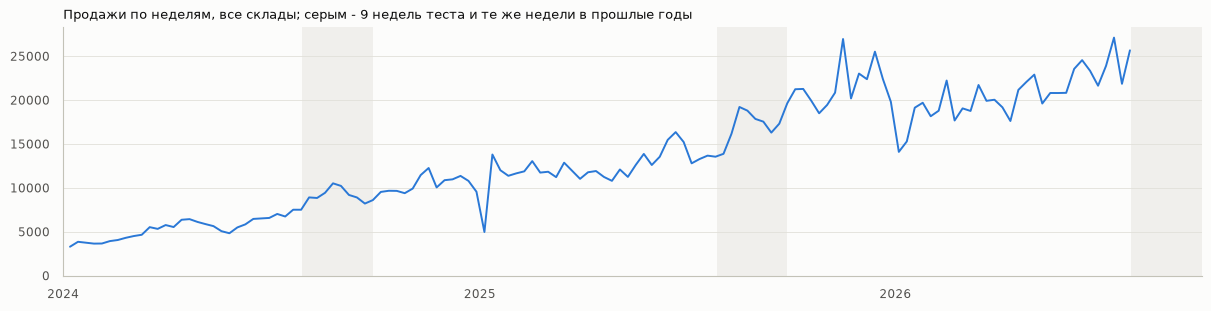

count    8789.000
mean        0.178
std         0.235
min         0.000
25%         0.031
50%         0.078
75%         0.234
90%         0.547
max         1.000
dtype: float64

In [4]:
fig, ax = plt.subplots(figsize=(12, 3), layout="constrained")
sns.lineplot(weekly(), color=BLUE, ax=ax)
style_weekly(ax)
ax.set_title("Продажи по неделям, все склады; серым - 9 недель теста и те же недели в прошлые годы")
plt.show()

# в какой доле дней продаётся пара склад × товар (последние 64 дня)
active_share = (daily_history(sales, universe(sales, stock), 64) > 0).mean(axis=1)
active_share.describe(percentiles=[.25, .5, .75, .9]).round(3)

## 2. Склады

`warehouse_name` - склад отгрузки, по нему и считается прогноз.

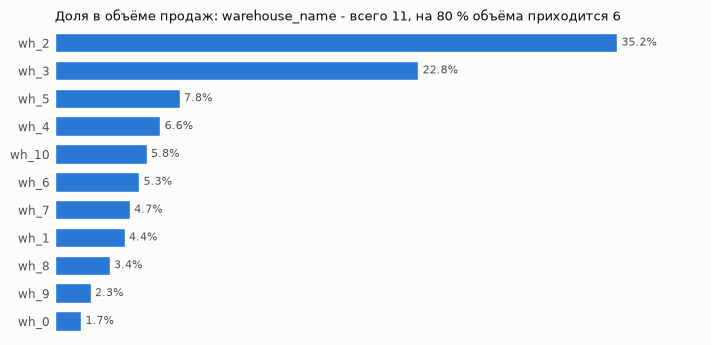

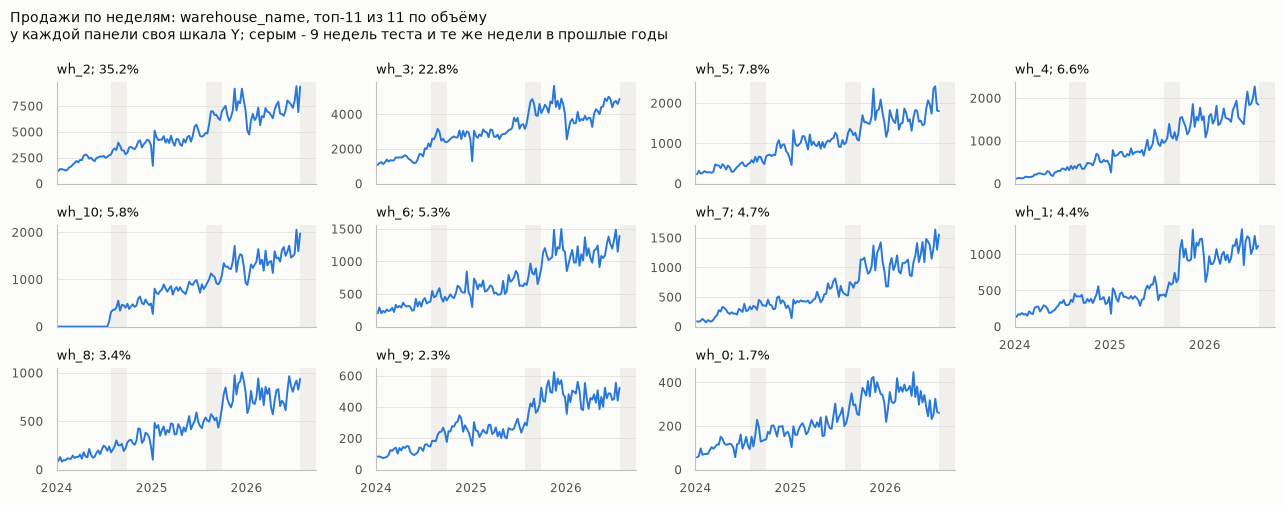

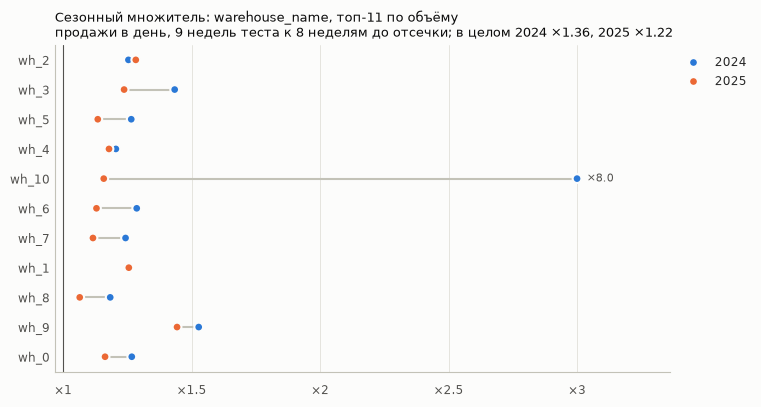

In [5]:
share_bar("warehouse_name")
weekly_panels("warehouse_name")
season_ratio("warehouse_name")

## 3. Департаменты

`composite_division` - в прогнозе департаменты суммируются, но разные паттерны внутри склада могут пригодиться.

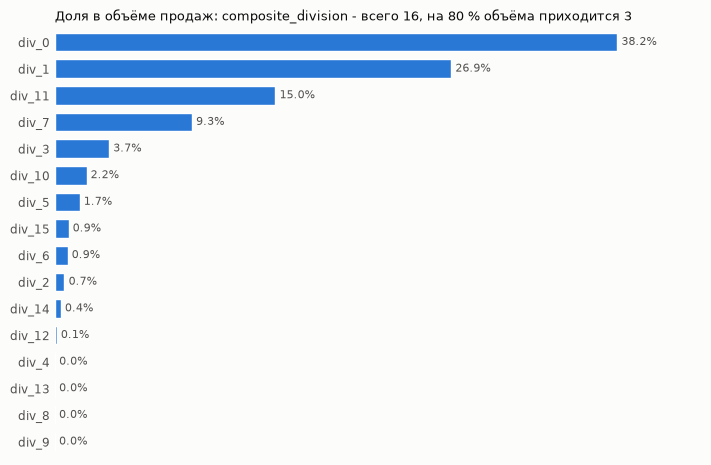

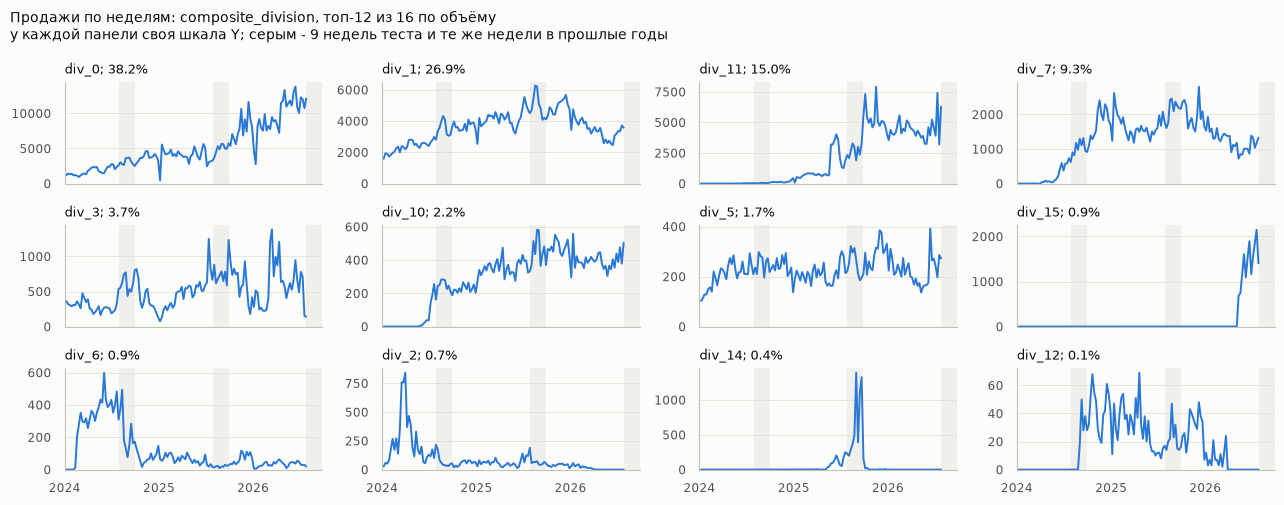

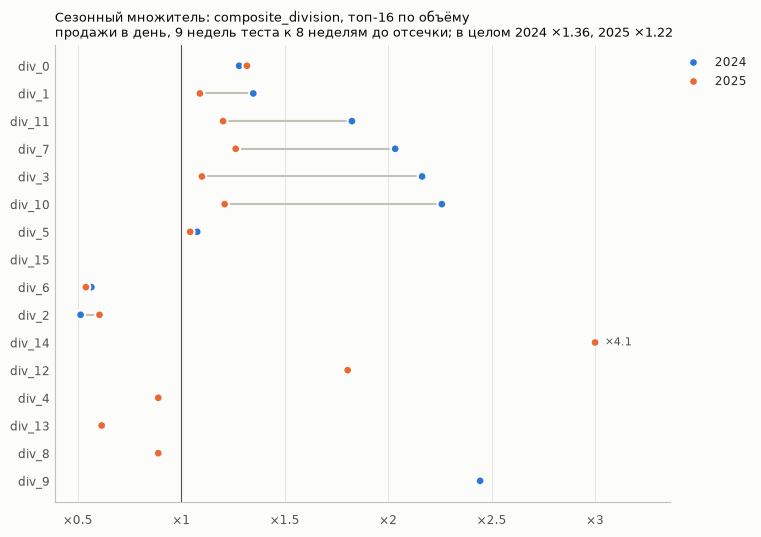

In [6]:
share_bar("composite_division", top=16)
weekly_panels("composite_division")
season_ratio("composite_division", top=16)

## 4. Города

`cities_name` - 209 значений, показываем топ по объёму.

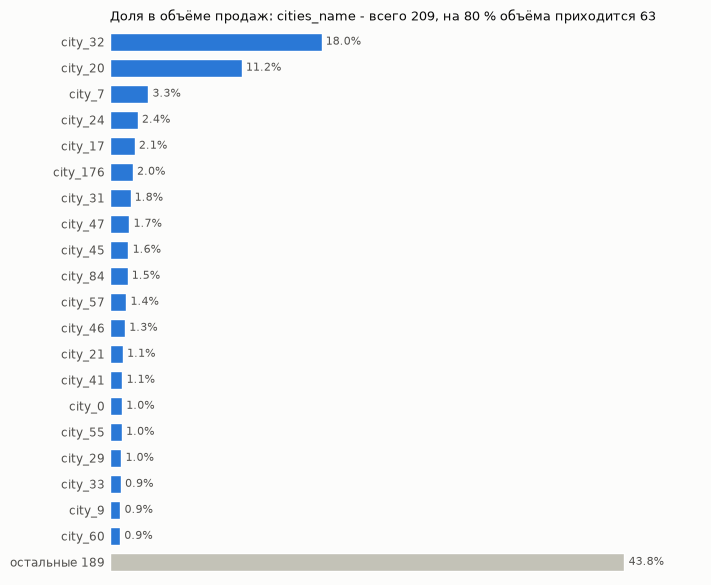

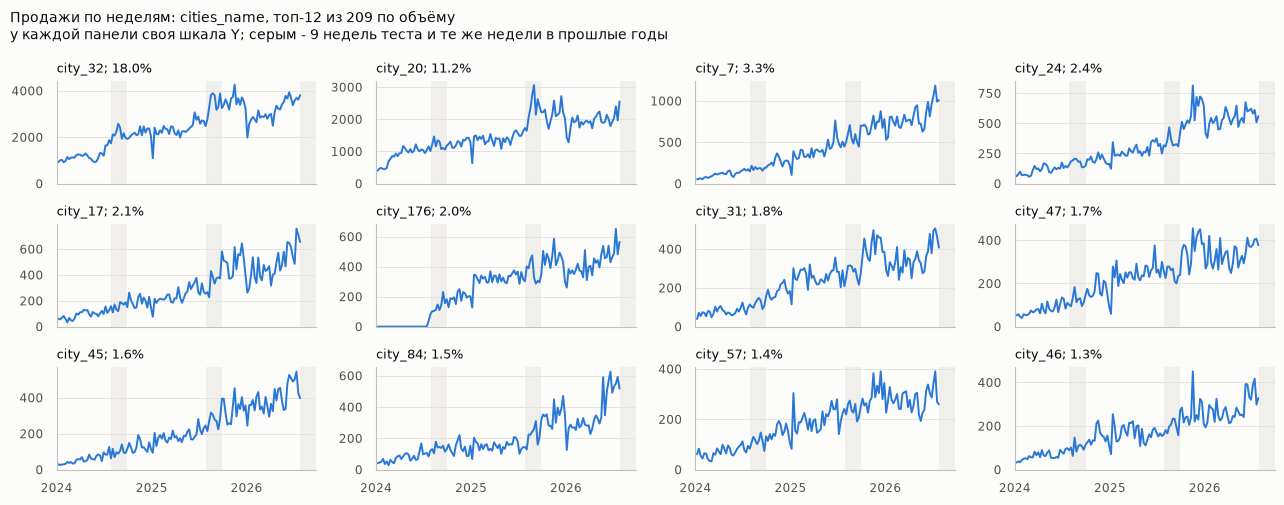

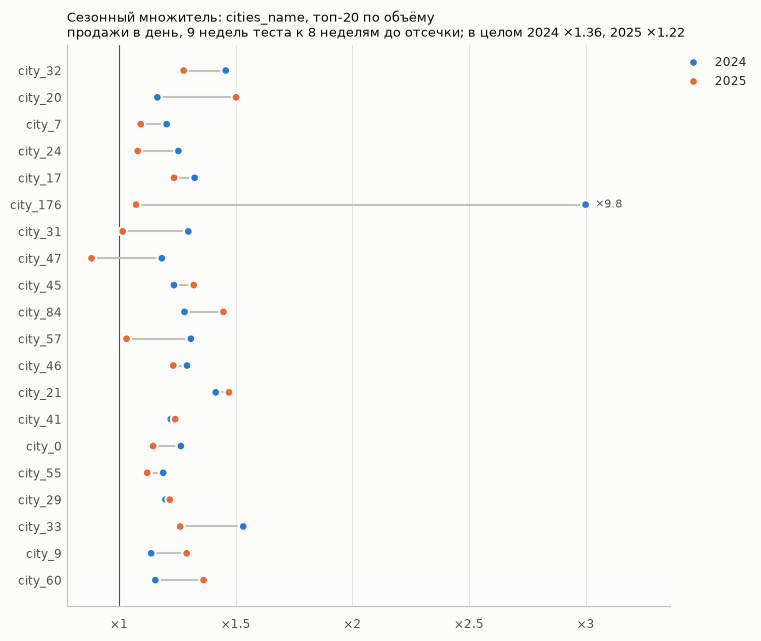

In [7]:
share_bar("cities_name", top=20)
weekly_panels("cities_name")
season_ratio("cities_name", top=20)

## 5. Категории

`category_lvl_3` почти пустая - смотрим уровни 1 и 2.

### 5.1. `category_lvl_1`

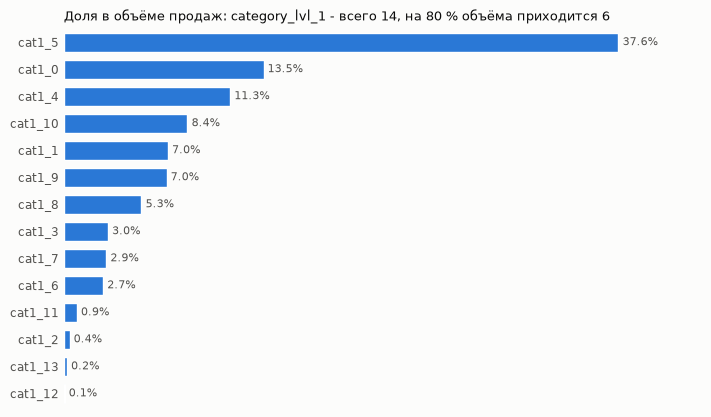

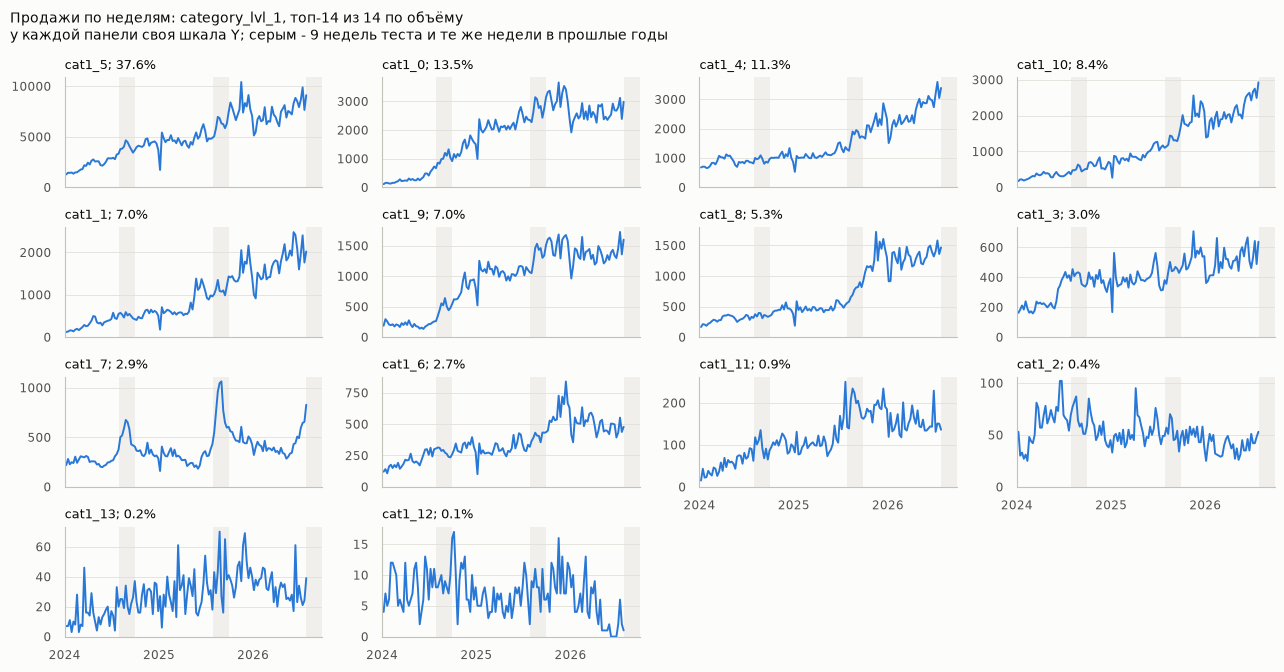

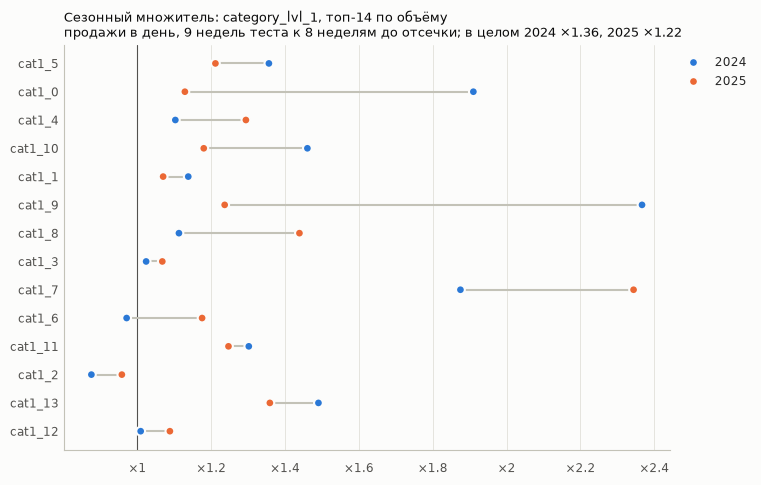

In [8]:
share_bar("category_lvl_1")
weekly_panels("category_lvl_1", top=16)
season_ratio("category_lvl_1")

### 5.2. `category_lvl_2`

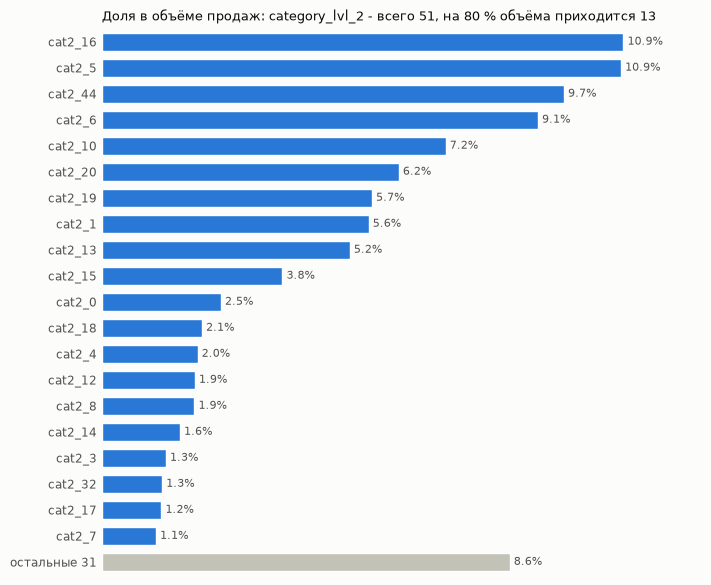

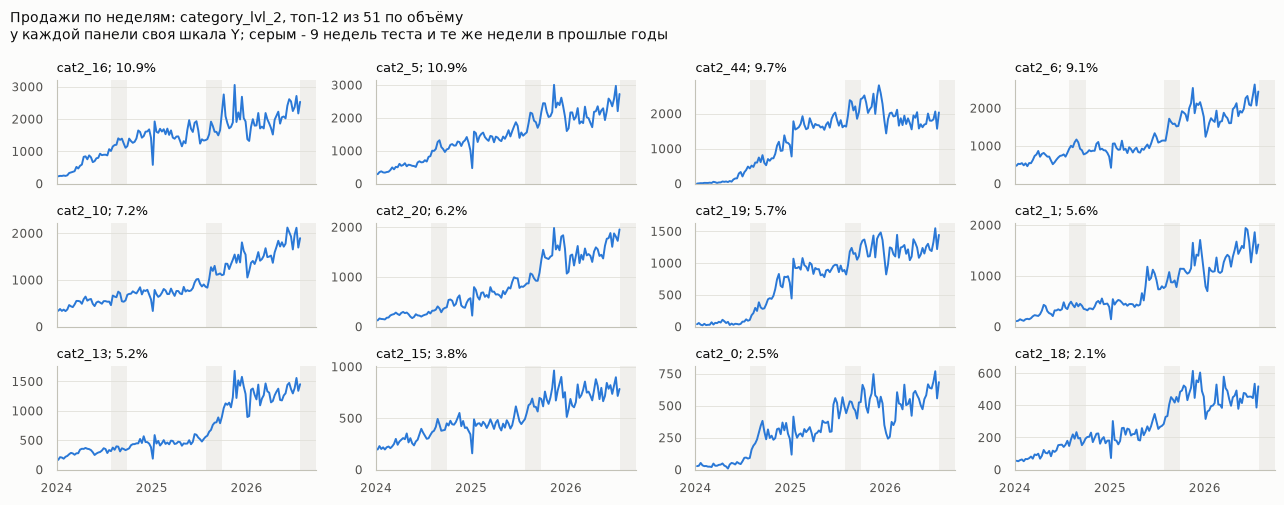

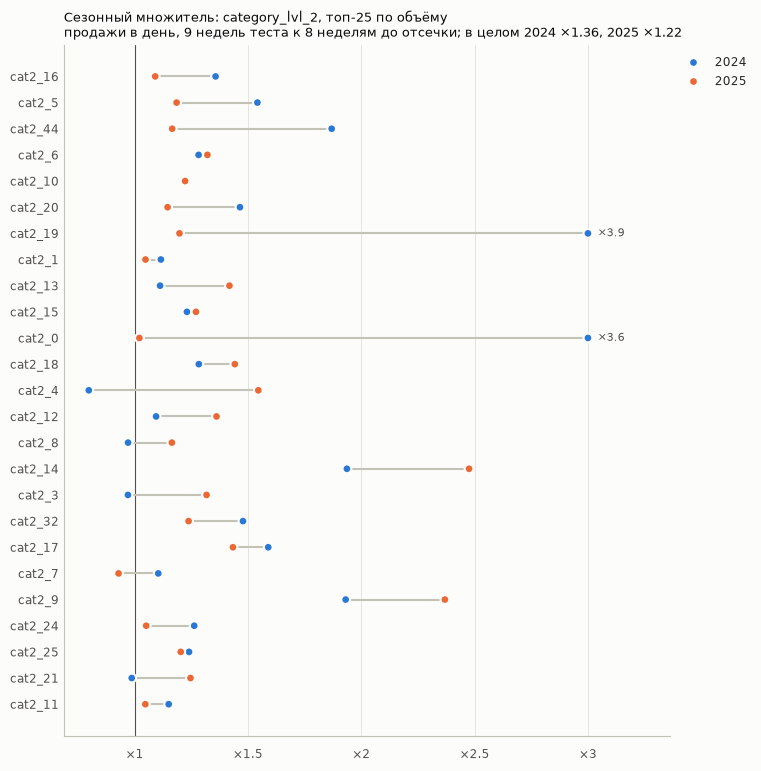

In [9]:
share_bar("category_lvl_2", top=20)
weekly_panels("category_lvl_2")
season_ratio("category_lvl_2", top=25)

## 6. Лаги, день недели и день месяца

Классический lag plot (точки "сегодня vs k дней назад") тут бесполезен: продажи пары - целые 0/1/2 с массой нулей, точки лягут в несколько кучек. Вместо него:
- профили по дню недели и дню месяца - продажи к скользящему среднему за 91 день (13 недель: тренд убран, каждый день недели в окне поровну);
- автокорреляция (ACF) по парам склад × товар - корреляция ряда пары с самим собой со сдвигом на k дней, среднее по группам частых, средних и редких. Чем медленнее спадает - тем дальше в прошлое имеет смысл смотреть.

ACF общих продаж специально не строим: картинка сильно зависит от способа убрать тренд (при делении на среднее за 28 дней появляется ложный пик на сдвиге 28).

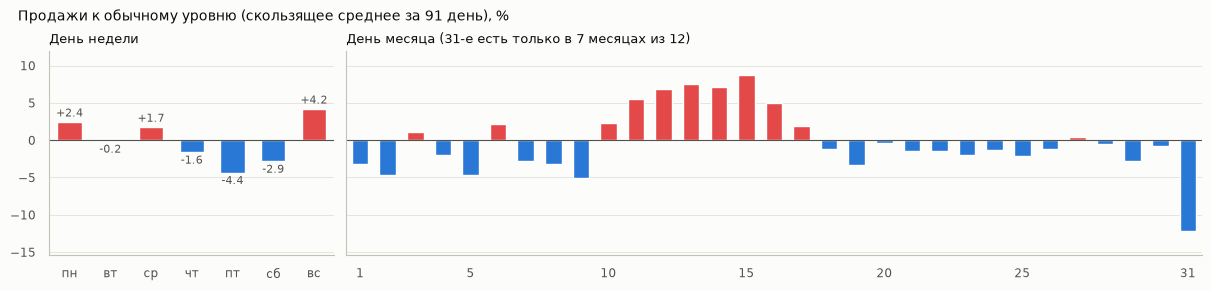

In [10]:
daily = sales.groupby("date").quantity.sum().resample("D").sum()
ratio = (daily / daily.rolling(91, center=True).mean()).dropna()   # тренд убран, дни недели в окне поровну
dow = (ratio.groupby(ratio.index.dayofweek).mean() - 1) * 100
dom = (ratio.groupby(ratio.index.day).mean() - 1) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 2.8), sharey=True, width_ratios=[1, 3], layout="constrained")
sns.barplot(x=["пн", "вт", "ср", "чт", "пт", "сб", "вс"], y=dow.to_numpy(), hue=dow.to_numpy() >= 0,
            palette=SIGN, legend=False, saturation=1, width=0.6, ax=ax1)
for bars in ax1.containers:
    ax1.bar_label(bars, fmt="{:+.1f}", padding=2, color=INK2, fontsize=8)
ax1.set_title("День недели")
sns.barplot(x=dom.index, y=dom.to_numpy(), hue=dom.to_numpy() >= 0, palette=SIGN, legend=False, saturation=1, width=0.6, ax=ax2)
ax2.set_xticks([d - 1 for d in (1, 5, 10, 15, 20, 25, 31)], [1, 5, 10, 15, 20, 25, 31])   # ось категориальная: позиция = день - 1
ax2.set(xlabel=None)
ax2.set_title("День месяца (31-е есть только в 7 месяцах из 12)")
for ax in (ax1, ax2):
    ax.axhline(0, color=INK2, lw=0.8)
ax1.margins(y=0.15)
fig.suptitle("Продажи к обычному уровню (скользящее среднее за 91 день), %", x=0.01, ha="left", fontsize=10, color=INK)
plt.show()

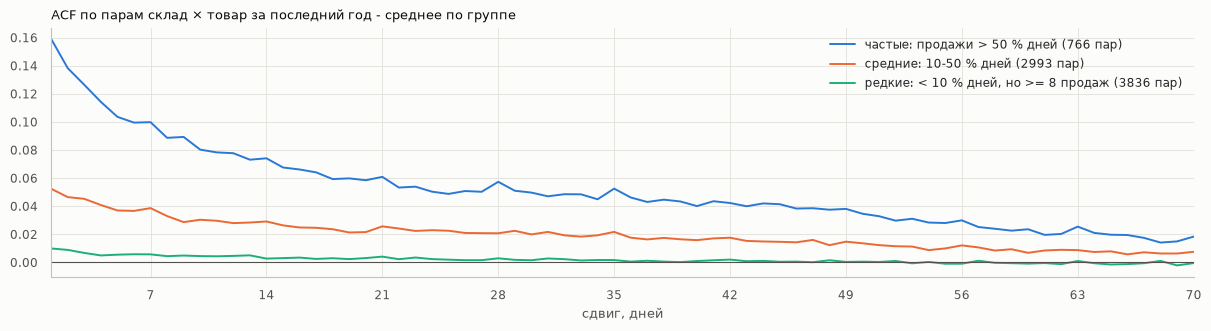

,частые: продажи > 50 % дней (766 пар),средние: 10-50 % дней (2993 пар),"редкие: < 10 % дней, но >= 8 продаж (3836 пар)"
1,0.159,0.052,0.010
7,0.100,0.039,0.006
14,0.074,0.029,0.003
28,0.057,0.021,0.003
56,0.030,0.012,-0.001


In [11]:
LAGS = 70
lags = np.arange(1, LAGS + 1)


def acf_rows(x, max_lag):
    # автокорреляция каждой строки x (ряды × дни) для сдвигов 1..max_lag
    x = x - x.mean(axis=1, keepdims=True)
    var = (x ** 2).sum(axis=1)
    return np.stack([(x[:, k:] * x[:, :-k]).sum(axis=1) / var for k in range(1, max_lag + 1)], axis=1)


hist = daily_history(sales, universe(sales, stock), 364).to_numpy()   # последний год: пары × дни
days_sold = (hist > 0).sum(axis=1)
share = days_sold / hist.shape[1]
groups = {
    "частые: продажи > 50 % дней": share > 0.5,
    "средние: 10-50 % дней": (share > 0.1) & (share <= 0.5),
    "редкие: < 10 % дней, но >= 8 продаж": (share <= 0.1) & (days_sold >= 8),
}
# среднее, а не медиана: у редкой пары на конкретном сдвиге совпадений продаж обычно нет, и медиана уходит в минус
acf_mean = pd.DataFrame({f"{name} ({mask.sum()} пар)": acf_rows(hist[mask], LAGS).mean(axis=0)
                         for name, mask in groups.items()}, index=lags)

df = acf_mean.rename_axis("сдвиг").reset_index().melt(id_vars="сдвиг", var_name="группа", value_name="acf")
fig, ax = plt.subplots(figsize=(12, 3.2), layout="constrained")
sns.lineplot(df, x="сдвиг", y="acf", hue="группа", palette=[BLUE, ORANGE, AQUA], ax=ax)
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xticks(range(0, LAGS + 1, 7))
ax.set_xlim(1, LAGS)
ax.grid(axis="x")
ax.set(xlabel="сдвиг, дней", ylabel=None)
sns.move_legend(ax, "upper right", frameon=False, title=None)
ax.set_title("ACF по парам склад × товар за последний год - среднее по группе")
plt.show()
acf_mean.loc[[1, 7, 14, 28, 56]].round(3)

## 7. Праздники и торговые даты

Как и в разделе 6: продажи к скользящему среднему за 91 день (`ratio` оттуда), в процентах. Смотрим ±10 дней вокруг каждой даты и усредняем по годам - лет в данных всего 2-3, так что профили шумные.
Официальный календарь (выходные и переносы) - из пакета `holidays`; переносов 2026 года в нём пока нет. Кроме официальных праздников - 1 сентября (попадает в окно теста) и торговые даты: 11.11 и чёрная пятница.

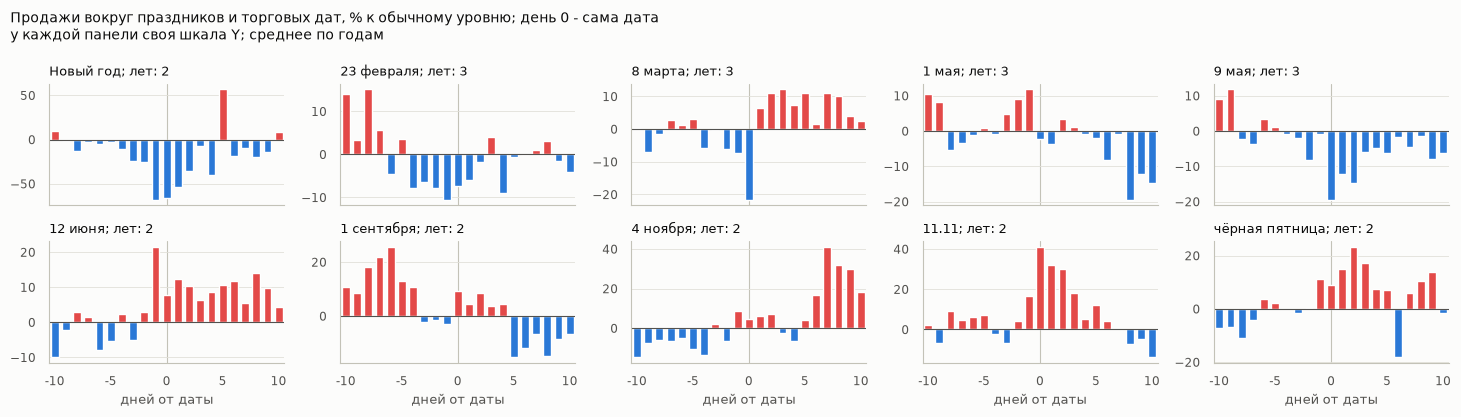

In [12]:
import holidays

ru = holidays.RU(years=range(2024, 2027))
hol = pd.Series(list(ru.values()), index=pd.to_datetime(list(ru.keys()))).sort_index()   # дата -> название

EVENTS = {name: [f"{y}-{md}" for y in (2024, 2025, 2026)] for name, md in [
    ("Новый год", "01-01"), ("23 февраля", "02-23"), ("8 марта", "03-08"), ("1 мая", "05-01"), ("9 мая", "05-09"),
    ("12 июня", "06-12"), ("1 сентября", "09-01"), ("4 ноября", "11-04"), ("11.11", "11-11")]}
EVENTS["чёрная пятница"] = ["2024-11-29", "2025-11-28"]

W = 10
dev = (ratio - 1) * 100


def event_profile(dates):
    # средний профиль ±W дней вокруг даты по годам; годы, где окно не покрыто данными, пропускаем
    profs = [dev.reindex(pd.date_range(d - pd.Timedelta(days=W), d + pd.Timedelta(days=W))).to_numpy()
             for d in pd.to_datetime(dates)]
    profs = [p for p in profs if np.isfinite(p).sum() > W]
    return np.nanmean(profs, axis=0), len(profs)


days = np.arange(-W, W + 1)
parts = []
for name, dates in EVENTS.items():
    p, n = event_profile(dates)
    parts.append(pd.DataFrame({"событие": f"{name}; лет: {n}", "день": days, "dev": p}))
ev = pd.concat(parts, ignore_index=True)

g = sns.catplot(ev, x="день", y="dev", col="событие", col_wrap=5, kind="bar", hue=ev.dev >= 0, palette=SIGN,
                legend=False, saturation=1, width=0.7, height=2.1, aspect=1.4, sharey=False)
for ax in g.axes.flat:
    ax.axvline(W, color=OTHER, lw=0.8, zorder=0)            # ось категориальная: день 0 стоит на позиции W
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks([0, 5, 10, 15, 20], [-10, -5, 0, 5, 10])
g.set_titles("{col_name}")
g.set_axis_labels("дней от даты", "")
g.figure.suptitle("Продажи вокруг праздников и торговых дат, % к обычному уровню; день 0 - сама дата\n"
                  "у каждой панели своя шкала Y; среднее по годам",
                  x=0.01, ha="left", fontsize=10, color=INK)
g.tight_layout()
plt.show()

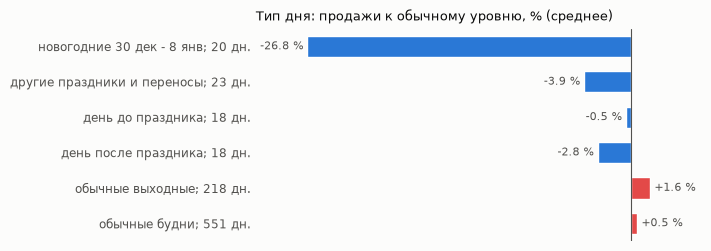

In [13]:
idx = dev.index
new_year = ((idx.month == 12) & (idx.day >= 30)) | ((idx.month == 1) & (idx.day <= 8))
KINDS = ["новогодние 30 дек - 8 янв", "другие праздники и переносы", "день до праздника",
         "день после праздника", "обычные выходные", "обычные будни"]
kind = pd.Series(np.select(
    [new_year, idx.isin(hol.index), idx.isin(hol.index - pd.Timedelta(days=1)),
     idx.isin(hol.index + pd.Timedelta(days=1)), idx.dayofweek >= 5],
    KINDS[:-1], KINDS[-1]), index=idx)
by_kind = dev.groupby(kind).agg(["mean", "size"]).reindex(KINDS)

fig, ax = plt.subplots(figsize=(7, 2.4), layout="constrained")
sns.barplot(x=by_kind["mean"].to_numpy(), y=[f"{k}; {n} дн." for k, n in by_kind["size"].items()],
            hue=by_kind["mean"].to_numpy() >= 0, palette=SIGN, legend=False, saturation=1, width=0.6, ax=ax)
ax.axvline(0, color=INK2, lw=0.8)
hbar_labels(ax, "{:+.1f} %")
ax.set_title("Тип дня: продажи к обычному уровню, % (среднее)")
plt.show()

In [14]:
# самые сильные отклонения от обычного уровня - кандидаты в выбросы при обучении
top = pd.concat([dev.nsmallest(10), dev.nlargest(10)]).round(0).to_frame("% к обычному")
top["день недели"] = np.array(["пн", "вт", "ср", "чт", "пт", "сб", "вс"])[top.index.dayofweek]
top["праздник"] = hol.reindex(top.index).fillna("")
top

,% к обычному,день недели,праздник
date,,,
2025-01-01,-85.0,ср,Новогодние каникулы
2024-12-31,-74.0,вт,Выходной (перенесено с 07.01.2024)
2025-01-02,-74.0,чт,Новогодние каникулы
2025-01-03,-64.0,пт,Новогодние каникулы
2025-12-31,-62.0,ср,Выходной (перенесено с 05.01.2025)
2025-01-05,-59.0,вс,Новогодние каникулы
2026-01-01,-48.0,чт,Новогодние каникулы
2026-01-12,-33.0,пн,
2026-01-02,-33.0,пт,Новогодние каникулы


### Что видно

- В окно теста (27 июля - 27 сентября) официальные праздники не попадают. Из эффектов там - 1 сентября: пик за 6-8 дней до неё (24-26 авг) +18...26 %, с 6 сентября -7...-15 % (по двум годам). И всплески в августе без праздника: 13 авг 2025 +50 %, 15 и 20 авг 2024 +38...39 % - похоже на акции.
- Новый год даёт главный провал: 31 дек - 2 янв до -85 %, в среднем за 30 дек - 8 янв -27 %; 6 янв 2025 - отскок +132 %.
- Остальные праздники слабые: в среднем -4 %, день до и после - около нуля. Заметны 8 марта (-22 % в сам день, потом неделя +10 %) и 9 мая (-19 %, ещё несколько дней -12...-15 %). 1 мая провала не даёт, вокруг 12 июня даже +5...15 %.
- Торговые даты сильнее праздников: 11.11 +41 % в день и +30 % ещё два дня (всплеск на +7...+9 дней у 4 ноября - это тоже 11.11), чёрная пятница +10...23 %, 14-15 дек 2025 +73 / +45 %.
- Признак "праздник" на тесте почти ничего не даст: праздников там нет. Новый год и 11.11 искажают средние и лаги в обучении - их можно помечать признаками или убирать из окон - что лучше, решает бэктест. Для конца августа может помочь признак "дней до 1 сентября".
- По категориям эффект праздников не смотрели - 8 марта, 23 февраля и 1 сентября наверняка бьют по разным категориям по-разному.

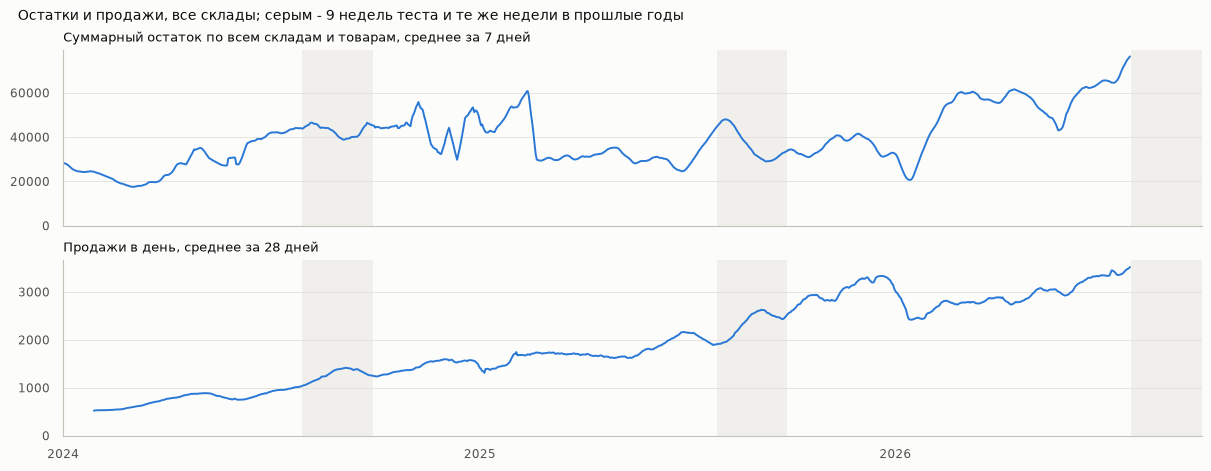

остаток в последние 10 дней / медиана за год: [1.59, 1.65, 1.65, 1.63, 1.63, 1.67, 1.7, 1.71, 1.74, 1.75]
запас в днях продаж на дату отсечки: 2024-07-28 - 41.1 | 2025-07-27 - 24.4 | 2026-07-26 - 22.5


In [15]:
# Суммарный остаток по всем парам: видно, затаривается ли компания перед сезоном
stock_tot = stock.groupby("date").stock.sum()   # дни без пропусков; отрицательных остатков (резерв) - 29 пар-дней, на сумму не влияют
pace = daily.rolling(28).mean()                 # продажи в день, среднее за 28 дней (daily - из раздела 6)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 4.6), sharex=True, layout="constrained")
sns.lineplot(stock_tot.rolling(7).mean(), color=BLUE, ax=ax1)
ax1.set_title("Суммарный остаток по всем складам и товарам, среднее за 7 дней")
sns.lineplot(pace, color=BLUE, ax=ax2)
ax2.set_title("Продажи в день, среднее за 28 дней")
for ax in (ax1, ax2):
    style_weekly(ax)
fig.suptitle("Остатки и продажи, все склады; серым - 9 недель теста и те же недели в прошлые годы",
             x=0.01, ha="left", fontsize=10, color=INK)
plt.show()

print("остаток в последние 10 дней / медиана за год:", (stock_tot.iloc[-10:] / stock_tot.iloc[-365:].median()).round(2).tolist())

# остаток в днях продаж: на сколько дней хватит запаса при текущем темпе
cover = stock_tot / pace
print("запас в днях продаж на дату отсечки:",
      " | ".join(f"{pd.Timestamp(c).date()} - {cover[c]:.1f}" for c in (FOLDS["season2024"], FOLDS["season2025"], CUTOFF)))


## 8. Категории 1_5 и 1_4

В разборе ошибок на главном фолде на эти две категории приходится почти половина всех ошибок: 1_5 - 34 % ошибок классификатора (`03_classifier`) и 36 % ошибки регрессора в штуках (`04_regressor`), 1_4 - 14 % и 12 %. Смотрим, чем они отличаются от остальных категорий (на графиках остальные - одна серая группа):
- паспорт: размер, ассортимент, концентрация, крупные строки, скидка, рост к прошлому году;
- доля в продажах и скидка по неделям;
- форма сезона по неделям в 2024 и 2025 годах;
- частота продаж пар перед сезоном 2025 и доля недель сезона с продажей;
- всплески - недели в 3+ раза выше обычной недели пары;
- рост перед отсечкой 2026 по подкатегориям и складам.

In [16]:
FOCUS = ["category_lvl_1_5", "category_lvl_1_4"]
GROUP_ORDER = FOCUS + ["остальные"]
PALETTE = {"cat1_5": BLUE, "cat1_4": ORANGE, "остальные": OTHER}
CUT25 = pd.Timestamp(FOLDS["season2025"])

grp = sales.category_lvl_1.where(sales.category_lvl_1.isin(FOCUS), "остальные")   # группа каждой строки продаж
pairs = universe(sales, stock)
pair_cat = pairs.article.map(sales.drop_duplicates("article").set_index("article").category_lvl_1)
pair_grp = pair_cat.where(pair_cat.isin(FOCUS), "остальные").to_numpy()        # товары без продаж - тоже "остальные"
money = np.exp(sales.sales_sum)                                               # суммы даны логарифмами - np.exp перед суммированием
disc = np.exp(sales.discount_sum).fillna(0.0)                                 # пустой discount_sum - скидки не было
recent = sales.date > CUTOFF - pd.Timedelta(days=56)                          # 8 недель до отсечки 2026
year_ago = sales.date.between(CUT25 - pd.Timedelta(days=55), CUT25)           # те же 8 недель 2025 года


def passport_row(rows, pair_rows):
    s = sales[rows]
    by_art = s.groupby("article").quantity.sum().sort_values(ascending=False)
    r, y = recent[rows], year_ago[rows]
    return {
        "товаров": s.article.nunique(),
        "подкатегорий lvl2": s.category_lvl_2.nunique(),
        "пар, %": pair_rows.mean() * 100,
        "штук за всё время, %": s.quantity.sum() / sales.quantity.sum() * 100,
        "штук за 8 недель до отсечки, %": s.quantity[r].sum() / sales.quantity[recent].sum() * 100,
        "денег, %": money[rows].sum() / money.sum() * 100,
        "штук у топ-20 % товаров, %": by_art.iloc[:len(by_art) // 5].sum() / by_art.sum() * 100,
        "штук из строк >= 10 шт., %": s.quantity[s.quantity >= 10].sum() / s.quantity.sum() * 100,
        "скидка за 8 недель, % суммы продаж": disc[rows][r].sum() / money[rows][r].sum() * 100,
        "рост за 8 недель к 2025, %": (s.quantity[r].sum() / s.quantity[y].sum() - 1) * 100,
    }


passport = pd.DataFrame({short(g): passport_row(grp == g, pair_grp == g) for g in GROUP_ORDER})
passport["все"] = passport_row(grp.notna(), pair_grp != "")
passport.round(1)

,cat1_5,cat1_4,остальные,все
товаров,268.0,122.0,409.0,799.0
подкатегорий lvl2,6.0,4.0,41.0,51.0
"пар, %",33.5,15.3,51.2,100.0
"штук за всё время, %",37.6,11.3,51.2,100.0
"штук за 8 недель до отсечки, %",36.0,13.1,51.0,100.0
"денег, %",47.8,6.7,45.6,100.0
"штук у топ-20 % товаров, %",61.0,46.1,63.0,60.5
"штук из строк >= 10 шт., %",0.5,2.1,0.7,0.8
"скидка за 8 недель, % суммы продаж",35.9,7.8,10.5,21.5
"рост за 8 недель к 2025, %",65.1,134.7,58.9,68.3


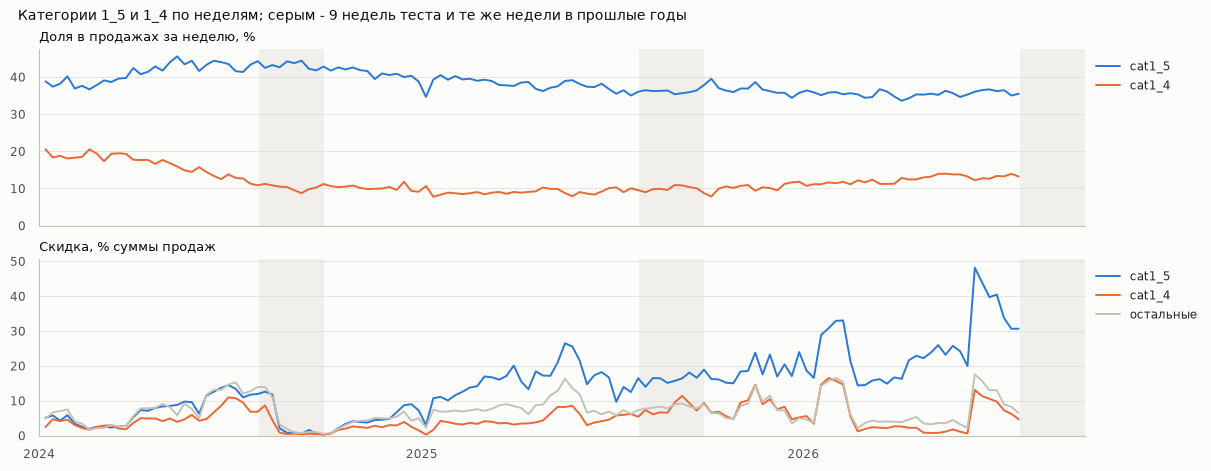

In [17]:
# по неделям: доля двух категорий в продажах и скидка (доля от суммы продаж) у всех трёх групп
by_week = (pd.DataFrame({"date": sales.date, "grp": grp.map(short), "quantity": sales.quantity, "money": money, "disc": disc})
           .groupby([pd.Grouper(key="date", freq="W"), "grp"]).sum())
by_week = by_week[by_week.index.get_level_values("date") <= sales.date.max()]       # неполную последнюю неделю отбрасываем
q = by_week.quantity.unstack()
cat_share = q[["cat1_5", "cat1_4"]].div(q.sum(axis=1), axis=0) * 100
discount = (by_week.disc / by_week.money).unstack()[list(PALETTE)] * 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 4.6), sharex=True, layout="constrained")
sns.lineplot(cat_share, palette=PALETTE, dashes=False, ax=ax1)
ax1.set_title("Доля в продажах за неделю, %")
sns.lineplot(discount, palette=PALETTE, dashes=False, ax=ax2)
ax2.set_title("Скидка, % суммы продаж")
for ax in (ax1, ax2):
    style_weekly(ax)
    sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), frameon=False, title=None)
fig.suptitle("Категории 1_5 и 1_4 по неделям; серым - 9 недель теста и те же недели в прошлые годы",
             x=0.01, ha="left", fontsize=10, color=INK)
plt.show()

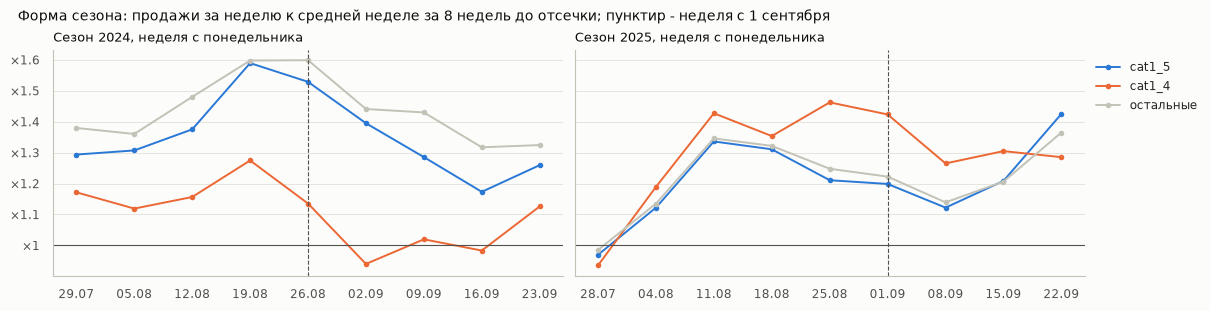

In [18]:
# форма сезона: каждая из 9 недель после отсечки к средней неделе за 8 недель до неё
fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharey=True, layout="constrained")
for ax, (y, cut) in zip(axes, (("2024", FOLDS["season2024"]), ("2025", FOLDS["season2025"]))):
    cut = pd.Timestamp(cut)
    s = sales[sales.date.between(cut - pd.Timedelta(days=55), cut + pd.Timedelta(days=63))]
    week = (((s.date - cut).dt.days - 1) // 7 + 1).rename("неделя")              # -7...0 - 8 недель до отсечки, 1...9 - сезон
    q = s.quantity.groupby([grp.loc[s.index].map(short), week]).sum().unstack()
    lift = q.loc[:, 1:].div(q.loc[:, :0].mean(axis=1), axis=0).T[list(PALETTE)]
    sns.lineplot(lift, palette=PALETTE, dashes=False, marker="o", markersize=4, markeredgewidth=0, ax=ax)
    ax.axhline(1, color=INK2, lw=0.8)
    ax.axvline(((pd.Timestamp(f"{y}-09-01") - cut).days - 1) // 7 + 1, color=INK2, lw=0.8, ls="--")
    ax.set_xticks(range(1, HORIZON + 1), [f"{cut + pd.Timedelta(days=7 * i - 6):%d.%m}" for i in range(1, HORIZON + 1)])
    ax.yaxis.set_major_formatter("×{x:g}")
    ax.set(xlabel=None, ylabel=None)
    ax.set_title(f"Сезон {y}, неделя с понедельника")
axes[0].get_legend().remove()
sns.move_legend(axes[1], "upper left", bbox_to_anchor=(1, 1), frameon=False, title=None)
fig.suptitle("Форма сезона: продажи за неделю к средней неделе за 8 недель до отсечки; пунктир - неделя с 1 сентября",
             x=0.01, ha="left", fontsize=10, color=INK)
plt.show()

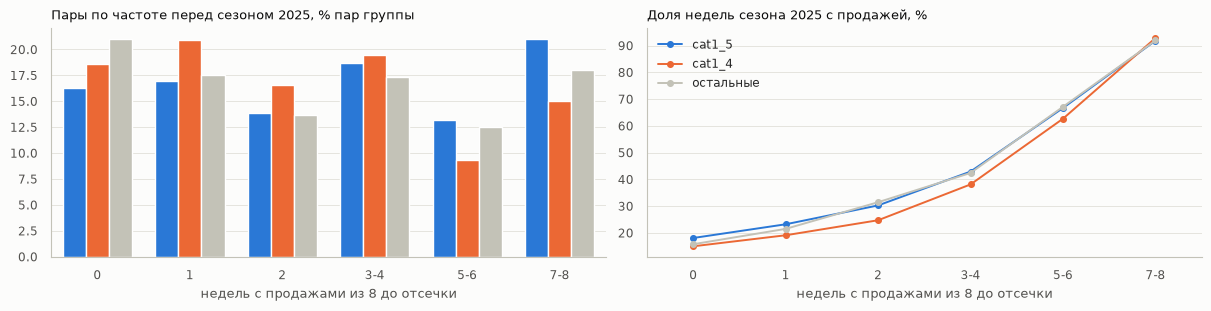

группа                            cat1_5  cat1_4  остальные
пары                     остаток                           
редкие: <= 2 недель из 8 есть       30.2    22.9       29.0
                         нет        22.7    19.0       21.1
частые: 3+ недель        есть       82.9    81.5       83.9
                         нет        54.8    48.4       54.0

In [19]:
# пары перед сезоном 2025: сколько недель из 8 до отсечки продавали - и в какой доле недель сезона продали
before = weekly_matrix(sales, pairs, CUT25 - pd.Timedelta(days=55), 8).to_numpy()
after = weekly_matrix(sales, pairs, CUT25 + pd.Timedelta(days=1), HORIZON).to_numpy()
stock_cut = stock[stock.date == CUT25].groupby(KEY).stock.sum().reindex(pd.MultiIndex.from_frame(pairs)).fillna(0)
n_sold = (before > 0).sum(axis=1)
pf = pd.DataFrame({
    "группа": [short(g) for g in pair_grp],
    "частота": pd.cut(n_sold, [-1, 0, 1, 2, 4, 6, 8], labels=["0", "1", "2", "3-4", "5-6", "7-8"]),
    "остаток": np.where(stock_cut.to_numpy() > 0, "есть", "нет"),             # на начало дня отсечки
    "продажи": (after > 0).mean(axis=1) * 100,                                  # доля недель сезона с продажей, %
})
pct = pf.groupby("группа")["частота"].value_counts(normalize=True).mul(100).rename("пар, %").reset_index()
p_sale = pf.groupby(["частота", "группа"], observed=True)["продажи"].mean().reset_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3), layout="constrained")
sns.barplot(pct, x="частота", y="пар, %", hue="группа", hue_order=list(PALETTE), palette=PALETTE,
            saturation=1, width=0.75, ax=ax1)
ax1.set_title("Пары по частоте перед сезоном 2025, % пар группы")
ax1.get_legend().remove()
sns.pointplot(p_sale, x="частота", y="продажи", hue="группа", hue_order=list(PALETTE), palette=PALETTE,
              markersize=4, linewidth=1.4, ax=ax2)
ax2.set_title("Доля недель сезона 2025 с продажей, %")
sns.move_legend(ax2, "upper left", frameon=False, title=None)
for ax in (ax1, ax2):
    ax.set(xlabel="недель с продажами из 8 до отсечки", ylabel=None)
plt.show()

# то же с разбивкой по остатку: редкие пары - продавали не больше 2 недель из 8
pf["пары"] = np.where(n_sold <= 2, "редкие: <= 2 недель из 8", "частые: 3+ недель")
pf.pivot_table(index=["пары", "остаток"], columns="группа", values="продажи", aggfunc="mean")[list(PALETTE)].round(1)

In [20]:
# всплеск - неделя пары от 5 шт. и в 3+ раза выше обычной: среднего ненулевых недель за 8 недель до неё (если их было 3+)
first = sales.date.min() + pd.Timedelta(days=(7 - sales.date.min().weekday()) % 7)      # первый понедельник
n_weeks = (last_full_sunday(sales.date.max()) - first).days // 7 + 1
wq = weekly_matrix(sales, pairs, first, n_weeks).to_numpy()                               # пары × недели
zero = np.zeros((len(wq), 1))
csum, cnz = np.hstack([zero, wq.cumsum(1)]), np.hstack([zero, (wq > 0).cumsum(1)])       # суммы недель 0...j-1
j = np.arange(n_weeks)
lo = np.maximum(j - 8, 0)
n8 = cnz[:, j] - cnz[:, lo]
typical = np.where(n8 >= 3, (csum[:, j] - csum[:, lo]) / np.maximum(n8, 1), np.nan)
spike = wq >= np.maximum(5, 3 * typical)                                                  # нет обычного уровня -> не всплеск

# по строкам продаж: самая крупная строка (день × город × департамент) и число городов за пару-неделю
s = sales[sales.date >= first]
pw = s.groupby([s.warehouse_name, s.article, ((s.date - first).dt.days // 7).rename("week")]).agg(
    max_row=("quantity", "max"), cities=("cities_name", "nunique"))
grid = dict(index=pd.MultiIndex.from_frame(pairs), columns=range(n_weeks), fill_value=0)
max_row = pw.max_row.unstack(fill_value=0).reindex(**grid).to_numpy()
cities = pw.cities.unstack(fill_value=0).reindex(**grid).to_numpy()


def spike_stats(m):
    x, sp = wq[m], spike[m]
    per_art = pd.DataFrame(sp).groupby(pairs.article.to_numpy()[m]).sum().to_numpy()    # складов со всплеском у товара за неделю
    repeat = sp.sum(axis=1)[:, None] >= 3
    return {
        "недель-всплесков, % недель с продажами": sp.sum() / (x > 0).sum() * 100,
        "штук во всплесках, %": x[sp].sum() / x.sum() * 100,
        "одна строка - половина недели и больше, % всплесков": (2 * max_row[m][sp] >= x[sp]).mean() * 100,
        "городов за неделю-всплеск, медиана": np.median(cities[m][sp]),
        "городов за обычную неделю с продажами, медиана": np.median(cities[m][(x > 0) & ~sp]),
        "всплеск только на одном складе товара, %": (per_art == 1).sum() / (per_art >= 1).sum() * 100,
        "штук всплесков у пар с 3+ всплесками, %": x[sp & repeat].sum() / x[sp].sum() * 100,
    }


pd.DataFrame({short(g): spike_stats(pair_grp == g) for g in GROUP_ORDER}).round(1)

,cat1_5,cat1_4,остальные
"недель-всплесков, % недель с продажами",1.2,1.1,1.3
"штук во всплесках, %",2.7,3.7,3.1
"одна строка - половина недели и больше, % всплесков",15.3,22.8,15.9
"городов за неделю-всплеск, медиана",4.0,3.0,4.0
"городов за обычную неделю с продажами, медиана",1.0,1.0,1.0
"всплеск только на одном складе товара, %",91.6,94.8,91.0
"штук всплесков у пар с 3+ всплесками, %",47.1,47.6,47.1


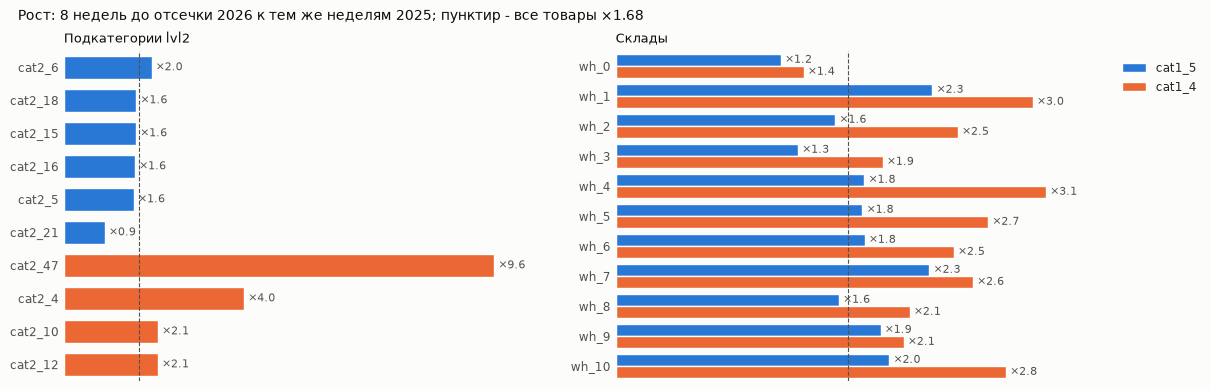

In [21]:
# рост перед отсечкой 2026: 8 недель до 2026-07-26 к тем же неделям 2025 - по подкатегориям и складам
total_growth = sales.quantity[recent].sum() / sales.quantity[year_ago].sum()
fs = sales[sales.category_lvl_1.isin(FOCUS)]
fs = pd.DataFrame({"категория": fs.category_lvl_1.map(short), "подкатегория": fs.category_lvl_2.map(short),
                   "склад": fs.warehouse_name.map(short), "quantity": fs.quantity,
                   "период": np.select([recent[fs.index].to_numpy(), year_ago[fs.index].to_numpy()], ["2026", "2025"], "")})


def growth(by):
    v = fs[fs["период"] != ""].groupby(["категория", by, "период"]).quantity.sum().unstack(fill_value=0)
    return (v["2026"] / v["2025"]).rename("рост").reset_index()


fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
g = growth("подкатегория").sort_values(["категория", "рост"], ascending=False)
sns.barplot(g, x="рост", y="подкатегория", hue="категория", hue_order=["cat1_5", "cat1_4"], palette=PALETTE,
            dodge=False, saturation=1, width=0.7, ax=axes[0])
axes[0].set_title("Подкатегории lvl2")
g = growth("склад")
sns.barplot(g, x="рост", y="склад", hue="категория", hue_order=["cat1_5", "cat1_4"], palette=PALETTE,
            order=sorted(g["склад"].unique(), key=lambda s: int(s.rsplit("_", 1)[1])), saturation=1, width=0.8, ax=axes[1])
axes[1].set_title("Склады")
for ax in axes:
    hbar_labels(ax, "×{:.1f}")
    ax.axvline(total_growth, color=INK2, lw=0.8, ls="--")
axes[0].get_legend().remove()
sns.move_legend(axes[1], "upper left", bbox_to_anchor=(1, 1), frameon=False, title=None)
fig.suptitle(f"Рост: 8 недель до отсечки 2026 к тем же неделям 2025; пунктир - все товары ×{total_growth:.2f}",
             x=0.01, ha="left", fontsize=10, color=INK)
plt.show()

### Что видно

- 1_5 - самая большая категория: треть пар (33,5 %), 38 % штук и 48 % денег, поэтому на неё и приходится треть ошибок обеих моделей. По форме сезона и по связи "частота -> продажа" она почти совпадает с остальными: при той же частоте за 8 недель и том же остатке продаёт в той же доле недель. Лечить её отдельно незачем.
- Скидки у 1_5 в разы глубже, и они растут. За 8 недель до отсечки скидка - 36 % суммы продаж против 8-11 % у остальных, а перед отсечкой 2026 года - пик около 48 %, какого в истории не было. Признаки цены и скидки на тесте окажутся на краю того, на чём учились.
- 1_4 - редкая и рваная категория. 56 % пар продавали не больше 2 недель из 8 (у 1_5 - 47 %), частых (7-8 из 8) - 15 % против 21 %. При той же частоте и том же остатке пары 1_4 продают на 2-6 п. п. реже. Отсюда больше пропущенных продаж у классификатора - это свойство самих пар.
- Крупные разовые покупки в 1_4 втрое чаще. Строки от 10 штук дают 2,1 % штук против 0,5-0,7 %. Во всплеске 1_4 одна строка (день × город × департамент) даёт половину недели и больше в 23 % случаев, у остальных - в 15-16 %. Крупнейший промах регрессора - "201 штука при прогнозе 2" - как раз такая покупка, и по истории пары её не угадать.
- 1_4 быстро растёт к тесту: за 8 недель до отсечки 2026 года +135 % к тем же неделям 2025-го при +68 % в целом. Растут все подкатегории (×2,1...×9,6) и все склады (×1,4...×3,1), то есть это тренд всей категории, а не одного товара. Сезон у 1_4 тоже неустойчив: в 2024 году он слабее остальных, в 2025-м сильнее (×1,35-1,46 в августе против ×1,25-1,35).
- Всплески у всех групп одинаковые. Это 1,1-1,3 % недель с продажами и 3-4 % штук. 91-95 % всплесков - на одном складе (не общая акция), покупают в 3-4 городах вместо одного. Половину штук во всплесках дают пары, у которых таких недель было 3 и больше.
- У частых пар многое решает остаток: с остатком на начало дня отсечки они продают в 82-84 % недель сезона, без остатка - в 48-55 %. У редких пар разница меньше: 23-30 % против 19-23 %. Признаки остатков у моделей уже есть.
- У всех групп пик за 1-2 недели до 1 сентября, затем спад; отдельного эффекта у 1_5 и 1_4 не видно.
- Что проверить бэктестом:
  - тренд категории `cat_trend` - 4 недели к 24 по всей категории; сейчас тренд считается только у пары, товара и склада, а рост 1_4 - общекатегорийный;
  - признак "сколько всплесков у пары за 24 недели" - для регрессора на всех категориях;
  - множитель прогноза по категории для 1_4, раз она занижена (прогноз / факт 0,78) и быстро растёт.

  Оптовые разовые покупки по истории не предсказать - их ошибку остаётся принять.